# 24 Netzereignisse und Monitorstatus für die Karte

Teil 5: Anomalien und Monitoring

**Worum es geht**
- Der Tagesmonitor (Notebook 20) bewertet jede Station einzeln. Beginnen viele Alarme gleichzeitig, liegt die Ursache eher außerhalb des Hauses (Kälte, Vorlauf, Begehungswelle).
- Frage 1: Gibt es Tage mit mehr Alarmstarts als zufällig?
- Frage 2: Alarmieren Nachbarn im Leitungsnetz gemeinsam?
- Frage 3: Was folgt daraus für die Priorität, und welcher Status kommt auf die Karte?

**Daten**
- liest: bereinigte Stundenreihen, Alarme des Tagesmonitors, Leitungsgraph aus `Nodes_Edges.ods`, für Abschnitt 5 die lokale Handliste `data/manual/adressen_koordinaten.ods`
- schreibt: `outputs/monitor_status.csv`, `outputs/monitor_alarme.csv`, `outputs/netzereignistage.csv` (nur Zählernummern)
- vorher ausführen: Notebook 00

**Code**
- Logik in `src/netzereignisse.py`, Nachbarn aus `src/nachbarschaft.py`, Tests in `tests/test_netzereignisse.py` und `tests/test_nachbarschaft.py`

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import alarmbewertung as ab
from src import build_graph as bg
from src import load_begehungen as lb
from src import nachbarschaft as ns
from src import netzereignisse as ne
from src import stationsblatt as bl
from src import tagesmonitor as tm

warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

t0 = time.time()
e = bl.eingaben(ROOT)
erg = bl.rechne(e["serien"], e["termine"], e["anschlusswerte"], e["bhkw"],
                e["ohne_datum"], baujahr=e["baujahr"])
T = erg["tagesmonitor"]
einsatz = ne.einsaetze(T["alarme"])
beobachtet = tm.beobachtete_tage(T["verlauf"])
print(f"{len(e['serien'])} Stundenreihen aus NB 00, gerechnet in "
      f"{time.time() - t0:.0f} s")
print(f"{len(einsatz)} Alarme an {einsatz['meter'].nunique()} Stationen, "
      f"{len(beobachtet)} Stationen im Monitor")
display(pd.crosstab(einsatz["kanal"], einsatz["bewertung"], margins=True))

93 Stundenreihen aus NB 00, gerechnet in 22 s
491 Alarme an 84 Stationen, 89 Stationen im Monitor


bewertung,besser,schlechter,All
kanal,,,
kwh_pro_m3,96,152,248
log_volumen,148,95,243
All,244,247,491


## 1 Netzereignistage

- Zeitpunkt eines Alarms ist der geschätzte Beginn der Änderung. Der CUSUM (Summe der Abweichungen, schlägt an, wenn sie zu groß wird) braucht im Median acht Tage bis zur Schwelle.
- Je Tag wird gezählt, wie viele Stationen im Fenster ±3 Tage einen Alarm beginnen.
- Vergleich: Die Alarme jeder Station werden 1.000-mal zufällig innerhalb ihrer Überwachungstage verschoben.
- Netzereignis = Tageswert über dem 95-%-Quantil des größten Tageswerts der Zufallsläufe. Das schützt gegen viele Tests auf einmal. Getrennt nach Richtung, zur Prüfung auch mit ±1 und ±7 Tagen.

In [2]:
richtungen = {"alle": einsatz,
              "schlechter": einsatz[einsatz["bewertung"] == "schlechter"],
              "besser": einsatz[einsatz["bewertung"] == "besser"]}
netz_erg = {}
zeilen = []
for name, x in richtungen.items():
    for f in ne.FENSTER_SENSITIVITAET:
        r = ne.netztage(x, beobachtet, fenster=f, seed=0)
        netz_erg[(name, f)] = r
        zeilen.append({"richtung": name, "fenster ±Tage": f,
                       "alarme": r["n_einsaetze"], "schwelle Stationen": r["schwelle"],
                       "netztage": int(r["tage"]["netzereignis"].sum()),
                       "episoden": len(r["episoden"]),
                       "gleichzeitige Paare": r["paare_beobachtet"],
                       "zufall erwartet": r["paare_erwartet"],
                       "p global": r["p_global"]})
display(pd.DataFrame(zeilen).round(3))

,richtung,fenster ±Tage,alarme,schwelle Stationen,netztage,episoden,gleichzeitige Paare,zufall erwartet,p global
0,alle,1,465,10.0,9,4,2407.0,1357.460,0.001
1,alle,3,465,15.0,13,3,8944.0,6803.322,0.001
2,alle,7,465,24.0,0,0,29545.0,27653.733,0.018
3,schlechter,1,238,7.0,5,4,719.0,373.161,0.001
4,schlechter,3,238,10.0,4,1,2701.0,1917.709,0.001
5,schlechter,7,238,16.0,0,0,8912.0,8212.079,0.042
6,besser,1,240,7.0,5,2,807.0,362.607,0.001
7,besser,3,240,10.0,10,2,2943.0,1893.334,0.001
8,besser,7,240,15.0,11,1,10020.0,8266.740,0.001


- In allen Varianten gibt es 7 bis 123 % mehr gleichzeitige Stationspaare als zufällig (p global höchstens 0,04).
- Über alle Alarme zählen 465 statt 491, weil zwei Kanäle einer Station mit gleichem Starttag nur einmal zählen.
- Mit ±3 Tagen gibt es eine Episode für Verschlechterungen und zwei für Verbesserungen. Bei ±7 Tagen liegt für Verschlechterungen kein Tag über der Schwelle.

- Ab hier gilt das Fenster ±3 Tage.
- Grafik: beginnende Verschlechterungen und Verbesserungen je Tag mit Schwelle, darunter die Tagesmitteltemperatur.

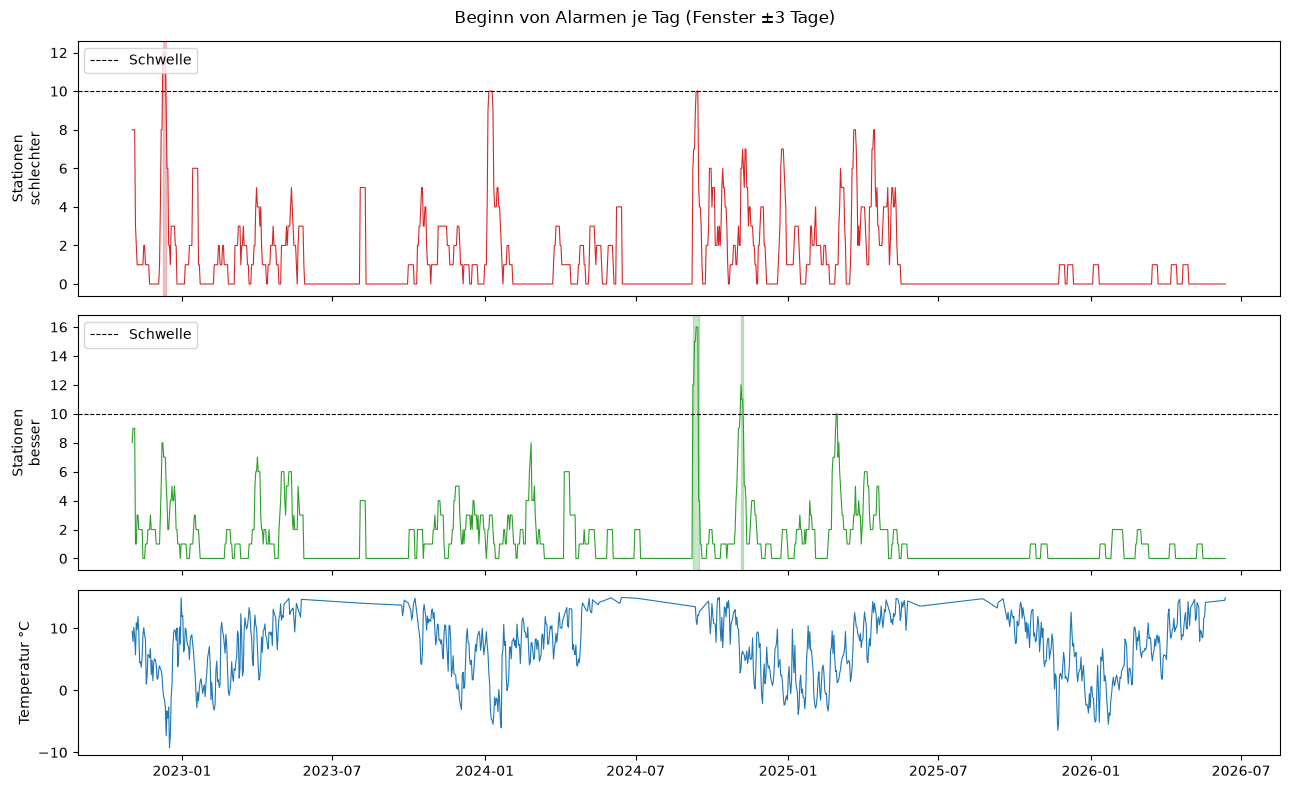

In [3]:
temp = T["verlauf"].groupby("datum")["t_mittel_c"].mean()
fig, ax = plt.subplots(3, 1, figsize=(13, 8), sharex=True,
                       gridspec_kw={"height_ratios": [2, 2, 1.3]})
for a, name, farbe in [(ax[0], "schlechter", "tab:red"),
                       (ax[1], "besser", "tab:green")]:
    r = netz_erg[(name, ne.FENSTER_TAGE)]
    t = r["tage"]
    a.plot(t["datum"], t["n_gleichzeitig"], color=farbe, lw=0.8)
    a.axhline(r["schwelle"], color="k", ls="--", lw=0.8, label="Schwelle")
    for ep in r["episoden"].itertuples():
        a.axvspan(ep.von, ep.bis + pd.Timedelta(days=1), color=farbe, alpha=0.25)
    a.set_ylabel(f"Stationen\n{name}")
    a.legend(loc="upper left")
ax[2].plot(temp.index, temp.to_numpy(), color="tab:blue", lw=0.8)
ax[2].set_ylabel("Temperatur °C")
fig.suptitle("Beginn von Alarmen je Tag (Fenster ±3 Tage)")
fig.tight_layout()
plt.show()

- Je Episode: Temperatur davor und danach, Median-Vorlauf aller Stationen, Begehungen in ±14 Tagen.

In [4]:
vl = {}
for meter, s in e["serien"].items():
    if "vl" in s.columns:
        vl[meter] = s.loc[s["power"] > 0, "vl"].resample("D").median()
vl_netz = pd.DataFrame(vl).median(axis=1)
termine = pd.Series(sorted(pd.Timestamp(d).normalize()
                           for v in e["termine"].values() for d in v))
tag = pd.Timedelta(days=1)
tage_je_station = {m: pd.DatetimeIndex(t).normalize() for m, t in beobachtet.items()}


def neustarts(von):
    #Stationen, die in den 30 Tagen davor nicht im Monitor waren
    n = 0
    for t in tage_je_station.values():
        if ((t >= von) & (t <= von + 5 * tag)).any() \
                and not ((t < von) & (t >= von - 30 * tag)).any():
            n += 1
    return n


def kontext(ep, x):
    vor = slice(ep.von - 10 * tag, ep.von - tag)
    in_ep = slice(ep.von, ep.bis + 7 * tag)
    sub = x[(x["beginn"] >= ep.von - 3 * tag) & (x["beginn"] <= ep.bis + 3 * tag)]
    return {"von": ep.von.date(), "bis": ep.bis.date(),
            "stationen": ep.n_stationen, "im monitor": ep.n_aktiv,
            "neustart nach pause": neustarts(ep.von),
            "T davor": temp[vor].mean(), "T danach": temp[in_ep].mean(),
            "VL davor": vl_netz[vor].median(), "VL danach": vl_netz[in_ep].median(),
            "begehungen ±14 T": int(((termine >= ep.von - 14 * tag)
                                     & (termine <= ep.bis + 14 * tag)).sum()),
            "anteil volumen": (sub["kanal"] == "log_volumen").mean()}


episoden = {}
for name in ("schlechter", "besser"):
    r = netz_erg[(name, ne.FENSTER_TAGE)]
    episoden[name] = pd.DataFrame([kontext(ep, richtungen[name])
                                   for ep in r["episoden"].itertuples()])
    print(name)
    display(episoden[name].round(1))

schlechter


,von,bis,stationen,im monitor,neustart nach pause,T davor,T danach,VL davor,VL danach,begehungen ±14 T,anteil volumen
0,2022-12-09,2022-12-12,12,40,0,3.4,-3.7,73.7,73.8,0,0.5


besser


,von,bis,stationen,im monitor,neustart nach pause,T davor,T danach,VL davor,VL danach,begehungen ±14 T,anteil volumen
0,2024-09-08,2024-09-14,16,53,52,NaN,12.0,72.9,71.4,36,0.8
1,2024-11-05,2024-11-07,12,65,10,10.2,5.3,70.2,72.4,12,0.4


- Verschlechterungswelle im Dezember 2022: nach einem Temperatursturz um rund 7 K (3,4 auf −3,7 °C), Vorlauf bei rund 74 °C, keine Begehungen. Das passt zu einer Kennlinie, die schnelle Kälteeinbrüche nicht abfängt (Tagesmittel desselben Tages, das Gebäude reagiert verzögert).
- Verbesserungswelle im September 2024: Neustart von 52 der 53 Stationen im Monitor nach der Sommerpause. Passt zu den 36 Begehungen im Umfeld, das Datum ist aber ein Artefakt.
- Anfang November 2024 fallen Abkühlung, höherer Vorlauf und zwölf Begehungen zusammen. Das lässt sich nicht trennen.

- Rangkorrelation über alle Tage: beginnende Alarme gegen Temperaturänderung (Mittel der folgenden minus Mittel der vorherigen sieben Tage).
- Die Tage hängen voneinander ab, der p-Wert ist deshalb nur grob.

In [5]:
dt = (temp.rolling(7).mean().shift(-7) - temp.rolling(7).mean()).rename("dT")
zeilen = []
for name in ("schlechter", "besser"):
    t = netz_erg[(name, ne.FENSTER_TAGE)]["tage"].set_index("datum")
    d = t.join(dt, how="inner").dropna()
    d = d[d["n_aktiv"] > 0]
    rho, p = stats.spearmanr(d["n_gleichzeitig"] / d["n_aktiv"], d["dT"])
    kalt = d["dT"] <= -5
    zeilen.append({"richtung": name, "tage": len(d), "rho": rho, "p": p,
                   "anteil bei dT <= -5 K": (d.loc[kalt, "n_gleichzeitig"]
                                             / d.loc[kalt, "n_aktiv"]).mean(),
                   "anteil sonst": (d.loc[~kalt, "n_gleichzeitig"]
                                    / d.loc[~kalt, "n_aktiv"]).mean(),
                   "tage dT <= -5 K": int(kalt.sum())})
display(pd.DataFrame(zeilen).round(3))

,richtung,tage,rho,p,anteil bei dT <= -5 K,anteil sonst,tage dT <= -5 K
0,schlechter,880,0.053,0.113,0.083,0.038,54
1,besser,880,-0.104,0.002,0.058,0.054,54


- An den 54 Tagen mit mindestens 5 K Abkühlung binnen einer Woche beginnen gut doppelt so oft Verschlechterungen: 8,3 % gegen 3,8 % der überwachten Stationen.
- Über alle Tage ist der Zusammenhang schwach (rho 0,05). Auch Verbesserungen beginnen bei Abkühlung etwas häufiger (5,8 % gegen 5,4 %).

## 2 Gleichzeitige Alarme bei Nachbarn

- Nachbarn wie in Notebook 23 über den logischen Leitungsgraphen, bis eine, zwei oder drei Kanten.
- Gleichzeitig heißt: Alarme derselben Richtung, deren Beginn höchstens drei Tage auseinander liegt.
- Vergleich: Die Stationen werden 10.000-mal zufällig auf die Knoten verteilt. So misst der Test nur den Effekt der Netznähe, nicht die netzweiten Ereignisse.

In [6]:
graph = bg.build_logical_graph()
im_graph = set(ns.meter_knoten(graph)) & set(beobachtet)
nachbarn = {k: ns.nachbarn(graph, k) for k in ns.KANTEN_SENSITIVITAET}
print(f"{len(im_graph)} Stationen im Monitor und im Graph")
zeilen = []
for k, nb in nachbarn.items():
    pr = ns.paare(nb)
    for name, x in richtungen.items():
        r = ne.nachbar_gleichzeitig(x, pr, fenster=ne.FENSTER_TAGE,
                                    stationen=im_graph, seed=0)
        zeilen.append({"kanten": k, "richtung": name, "paare": r["paare"],
                       "gleichzeitig": r["beobachtet"],
                       "zufall erwartet": r["erwartet"], "p": r["p"]})
nachbar_tab = pd.DataFrame(zeilen)
display(nachbar_tab.round(3))

79 Stationen im Monitor und im Graph


,kanten,richtung,paare,gleichzeitig,zufall erwartet,p
0,1,alle,51,17,13.862,0.191
1,1,schlechter,51,6,4.624,0.307
2,1,besser,51,10,5.430,0.035
3,2,alle,115,35,31.388,0.248
4,2,schlechter,115,11,10.481,0.480
5,2,besser,115,20,12.311,0.018
6,3,alle,180,59,49.152,0.060
7,3,schlechter,180,20,16.415,0.206
8,3,besser,180,28,19.305,0.026


- Gleichzeitige Nachbarpaare bei zwei Kanten, nur mit Zählernummern.

In [7]:
paare2 = ns.paare(nachbarn[ns.MAX_KANTEN])
treffer = []
for name in ("schlechter", "besser"):
    r = ne.nachbar_gleichzeitig(richtungen[name], paare2, fenster=ne.FENSTER_TAGE,
                                stationen=im_graph, n=1, seed=0)
    treffer.append(r["treffer"].assign(richtung=name))
treffer = pd.concat(treffer, ignore_index=True)
display(treffer.sort_values(["richtung", "beginn_a"]))

,meter_a,meter_b,beginn_a,beginn_b,abstand_tage,richtung
11,65273846,72135481,2022-11-02,2022-11-02,0,besser
22,68956367,72135463,2022-11-02,2022-11-02,0,besser
16,68956347,72135490,2023-05-01,2023-05-04,3,besser
17,68956348,68956367,2023-12-27,2023-12-30,3,besser
12,68956344,68956348,2023-12-29,2023-12-27,2,besser
20,68956361,68956365,2024-02-27,2024-02-28,1,besser
23,68956371,72135453,2024-02-29,2024-02-27,2,besser
18,68956353,80912195,2024-09-11,2024-09-11,0,besser
28,80912162,80912180,2024-09-11,2024-09-11,0,besser
29,80912162,80912197,2024-09-11,2024-09-11,0,besser


- Verschlechterungen: Nachbarn alarmieren nicht häufiger gemeinsam als zufällige Paare (p 0,21 bis 0,48).
- Verbesserungen kommen bei Nachbarn etwas häufiger gleichzeitig (p 0,018 bis 0,035 bei allen drei Weiten). Viele dieser Paare beginnen am 11.09.2024, das passt zu gemeinsamen Begehungsterminen.
- Nur 15 der 66 Alarme mit gleichzeitigem Nachbarn liegen an Netzereignistagen (Abschnitt 3).
- Wie in Notebook 23: kein Hinweis auf Probleme einzelner Stränge.

## 3 Markierung je Alarm und Wirkung auf die Priorität

- `netzereignis`: Der Alarm beginnt höchstens drei Tage neben einem Netzereignistag derselben Richtung.
- `nachbar_gleichzeitig`: Ein Nachbar (bis zwei Kanten) hat einen Alarm derselben Richtung, Beginn höchstens drei Tage daneben.
- Die Priorität aus Notebook 21 bleibt. Zur Prüfung wird sie zusätzlich ohne die Verschlechterungen an Netzereignistagen gerechnet.

In [8]:
markiert = []
for name in ("schlechter", "besser"):
    t = netz_erg[(name, ne.FENSTER_TAGE)]["tage"]
    markiert.append(ne.markiere(richtungen[name],
                                t.loc[t["netzereignis"], "datum"], paare2,
                                fenster=ne.FENSTER_TAGE))
markiert = pd.concat(markiert, ignore_index=True)
display(pd.crosstab(markiert["bewertung"],
                    [markiert["netzereignis"], markiert["nachbar_gleichzeitig"]],
                    margins=True))

prio = erg["prioritaet"]
ohne_netz = markiert[~(markiert["netzereignis"]
                       & (markiert["bewertung"] == "schlechter"))]
alle_alarme = T["alarme"].assign(
    meter=T["alarme"]["meter"].astype(int),
    datum=pd.to_datetime(T["alarme"]["datum"]).dt.normalize())
alarme_ohne = alle_alarme.merge(ohne_netz[["meter", "kanal", "datum"]],
                                on=["meter", "kanal", "datum"])
assert len(alarme_ohne) == len(ohne_netz)
prio_ohne = ab.prioritaet_je_winter(erg["markiert"], alarme_ohne)
vergleich = prio.merge(prio_ohne[["meter", "winter", "prioritaet"]],
                       on=["meter", "winter"], suffixes=("", "_ohne_netz"))
display(pd.crosstab(vergleich["prioritaet"], vergleich["prioritaet_ohne_netz"],
                    margins=True))

netzereignis         False       True       All
nachbar_gleichzeitig False True False True     
bewertung                                      
besser                 184   27    21   12  244
schlechter             210   24    10    3  247
All                    394   51    31   15  491

prioritaet_ohne_netz,hoch,mittel,niedrig,All
prioritaet,,,,
hoch,16,0,0,16
mittel,0,96,4,100
niedrig,0,0,95,95
All,16,96,99,211


In [9]:
geaendert = vergleich[vergleich["prioritaet"] != vergleich["prioritaet_ohne_netz"]]
display(geaendert[["meter", "winter", "auffaellig", "alarme_schlechter",
                   "prioritaet", "prioritaet_ohne_netz"]]
        .sort_values(["winter", "meter"]))

,meter,winter,auffaellig,alarme_schlechter,prioritaet,prioritaet_ohne_netz
3,61620222,22/23,False,1,mittel,niedrig
14,68956355,22/23,False,1,mittel,niedrig
25,69527340,22/23,False,1,mittel,niedrig
27,69631918,22/23,False,1,mittel,niedrig


- 46 der 491 Alarme beginnen an einem Netzereignistag (13 davon Verschlechterungen). 66 haben einen gleichzeitigen Nachbarn.
- Alle 16 Stationswinter mit hoher Priorität bleiben hoch.
- Vier fallen von mittel auf niedrig. Alle vier sind im Netzvergleich unauffällig und haben nur einen Verschlechterungsalarm, der in eine Netzwelle fällt.
- Der Nutzen liegt vor allem im Betrieb: einen neuen Alarm einordnen, bevor jemand hinfährt.

## 4 Monitorstatus für die Karte

- `outputs/monitor_status.csv`: je Station und Kernwinter Priorität, Netzwert, Rang, Fehlerbild, chronisch ja/nein und Alarmzahlen. Keine Adressen.
- Dazu `outputs/monitor_alarme.csv` und `outputs/netzereignistage.csv`.
- Notebook 33 legt alle drei auf eine Kopie der Karte aus Notebook 31.

In [10]:
fb = ab.fehlerbild_je_winter(erg["markiert"], list(erg["kennzahlen"]))
status = ne.monitor_status(prio, erg["markiert"], fb, erg["uebersicht"], markiert)
ziel = ROOT / "outputs" / "monitor_status.csv"
ziel.parent.mkdir(parents=True, exist_ok=True)
status.to_csv(ziel, index=False)
print(f"{len(status)} Zeilen, {status['meter'].nunique()} Stationen -> "
      f"{ziel.relative_to(ROOT)}")
#Alarme und Ereignistage für die Zeitachse der Karte
markiert.sort_values(["meter", "datum"]).to_csv(
    ziel.parent / "monitor_alarme.csv", index=False, date_format="%Y-%m-%d")
pd.concat([netz_erg[(name, ne.FENSTER_TAGE)]["episoden"]
           [["von", "bis", "n_stationen", "n_aktiv"]].assign(richtung=name)
           for name in ("schlechter", "besser")]).to_csv(
    ziel.parent / "netzereignistage.csv", index=False, date_format="%Y-%m-%d")
print(f"{len(markiert)} Alarme -> outputs/monitor_alarme.csv, Episoden -> "
      "outputs/netzereignistage.csv")
display(pd.crosstab(status["winter"], status["prioritaet"], margins=True))
display(status[status["prioritaet"] == "hoch"].sort_values(["winter", "rang"]).head(15))

211 Zeilen, 92 Stationen -> outputs/monitor_status.csv
491 Alarme -> outputs/monitor_alarme.csv, Episoden -> outputs/netzereignistage.csv


prioritaet,hoch,mittel,niedrig,All
winter,,,,
22/23,5,23,13,41
23/24,3,32,51,86
24/25,8,45,31,84
All,16,100,95,211


,meter,winter,prioritaet,auffaellig,score,rang,fehlerbild,chronisch,alarme_schlechter,alarme_besser,alarme_netzereignis,alarme_nachbar
11,68956351,22/23,hoch,True,2.443546,1.0,ventil,True,1,1,0,0
39,72167783,22/23,hoch,True,1.558427,3.0,unruhig,False,2,5,0,0
29,72135442,22/23,hoch,True,1.551508,4.0,ventil,True,1,1,0,0
34,72135480,22/23,hoch,True,1.495950,5.0,ventil,True,2,2,0,0
30,72135453,22/23,hoch,True,1.315033,6.0,durchfluss,True,2,1,0,0
65,68956372,23/24,hoch,True,2.451107,4.0,ventil,False,1,0,0,0
79,72135480,23/24,hoch,True,2.137159,5.0,ventil,True,2,2,0,0
75,72135453,23/24,hoch,True,1.956134,7.0,durchfluss,True,2,2,0,1
191,80912182,24/25,hoch,True,2.045287,1.0,ventil,True,2,1,1,1
155,72135442,24/25,hoch,True,1.935079,3.0,unruhig,True,2,2,0,0


## 5 Nachbarn über die Luftlinie

- Koordinaten aus der Handliste `adressen_koordinaten.ods` aus Notebook 31. Sie liegt nicht im Repository, nur lokal unter `data/manual/`.
- Die Nominatim-Positionen in `data/processed/hast_geocoded.csv` sind meist nur straßengenau und werden deshalb nicht genutzt.
- Test wie in Notebook 23, mit Nachbarn im Umkreis von 50, 100 und 200 m.

In [11]:
liste = ROOT / "data" / "manual" / "adressen_koordinaten.ods"
if not liste.exists():
    print("Übersprungen: data/manual/adressen_koordinaten.ods fehlt.")
else:
    pos = ns.positionen_aus_handliste(liste, lb.meter_to_address())
    netz = erg["markiert"]
    mit_pos = set(pos["meter"])
    print(f"{len(mit_pos)} Zähler mit Koordinate")
    zeilen = []
    for radius in ns.RADIUS_SENSITIVITAET:
        pr = ns.paare(ns.radius_nachbarn(pos, radius))
        for w, t in netz[netz["score"].notna()].groupby("winter"):
            j = ns.join_test(pr, dict(zip(t["meter"], t["auffaellig"])),
                             stationen=mit_pos)
            s = ns.score_test(pr, dict(zip(t["meter"], t["score"])),
                              stationen=mit_pos)
            zeilen.append({"radius m": radius, "winter": w, "paare": j["paare"],
                           "beide auffaellig": j["beobachtet"],
                           "zufall erwartet": j["erwartet"], "p Paare": j["p"],
                           "rho Score": s["beobachtet"], "p Score": s["p"]})
        g = ne.nachbar_gleichzeitig(richtungen["schlechter"], pr,
                                    stationen=mit_pos & set(beobachtet), seed=0)
        zeilen.append({"radius m": radius, "winter": "Alarme schlechter",
                       "paare": g["paare"], "beide auffaellig": g["beobachtet"],
                       "zufall erwartet": g["erwartet"], "p Paare": g["p"]})
    display(pd.DataFrame(zeilen).round(3))

102 Zähler mit Koordinate


,radius m,winter,paare,beide auffaellig,zufall erwartet,p Paare,rho Score,p Score
0,50,22/23,46,0,1.028,1.000,0.323,0.008
1,50,23/24,156,3,1.646,0.214,0.109,0.058
2,50,24/25,163,3,3.108,0.603,0.152,0.023
3,50,Alarme schlechter,157,20,12.978,0.036,NaN,NaN
4,100,22/23,193,3,4.333,0.829,-0.026,0.393
5,100,23/24,543,8,5.746,0.200,-0.027,0.593
6,100,24/25,538,7,10.190,0.877,0.006,0.259
7,100,Alarme schlechter,542,59,44.920,0.021,NaN,NaN
8,200,22/23,461,11,10.367,0.457,0.035,0.011
9,200,23/24,1428,19,15.143,0.189,0.010,0.102


- Gemeinsam auffällig werden Nachbarn in keinem Radius und keinem Winter häufiger als zufällig (p zwischen 0,2 und 1,0).
- Die Scores sehr naher Häuser hängen leicht zusammen: bei 50 m in allen drei Wintern positiv (rho 0,32, 0,11 und 0,15 bei p 0,008, 0,058 und 0,023). Bei 100 m verschwindet das.
- Gleichzeitige Verschlechterungen sind in allen drei Radien etwas häufiger als zufällig (50 m: 20 statt 13 Paare, p 0,036; 100 m: 59 statt 45, p 0,021; 200 m: 145 statt 120, p 0,010).
- Bei zwölf Tests sind einzelne kleine p-Werte Zufall. Die gleichzeitigen Verschlechterungen zeigen aber in allen drei Radien in dieselbe Richtung. Der 50-m-Effekt passt eher zu ähnlichen Gebäuden als zu einem Netzfehler.

## Zusammenfassung & Bewertung

**Ergebnis**
- Alarme häufen sich an einzelnen Tagen netzweit.
- Die Verschlechterungswelle (Dezember 2022) fällt auf einen Kälteeinbruch bei unverändertem Vorlauf. Das ist ein Hinweis auf eine Schwäche der Kennlinie, nicht auf Hausfehler.
- Die Verbesserungswelle im September 2024 ist ein Neustart-Artefakt.
- Jeder Alarm trägt jetzt `netzereignis` und `nachbar_gleichzeitig`. Alarme an Netzereignistagen zuerst gegen Wetter und Netz prüfen. Die Spitze der Prioritätsliste bleibt gleich.

**Belastbar**
- Im Leitungsgraphen alarmieren Nachbarn bei Verschlechterungen nicht gemeinsam. Die Auffälligkeiten passen zu Ursachen an der einzelnen Station.

**Schwach**
- Der Graph hat keine Längen und Drücke.
- Die Schwelle ist streng: Wellen mit fünf oder sechs Stationen fallen darunter.
- Der Alarmbeginn ist nur geschätzt.
- Über die Luftlinie beginnen Verschlechterungen naher Häuser etwas häufiger gleichzeitig (p 0,01 bis 0,04). Ob das an ähnlichen Gebäuden liegt, ist nicht geprüft.

**Offen**
- Die Kennlinie mit geglätteter oder um einen Tag verzögerter Temperatur rechnen und prüfen, ob die Wellen kleiner werden.